# <font color='magenta'>A sparse autoencoder for MNIST</font>

This notebook was made with plenty of help from ChatGPT.

### <font color='blue'>1. Start with the usual includes</font>

In [1]:



%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as tfunc
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

### <font color='blue'>2. Load in the MNIST data</font>

In [2]:
device = 'mps' # This is good enough for us, but change it if you like

transform = transforms.ToTensor()  # Map pixel values into [0,1]
train_ds = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
test_ds  = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

batch_size = 256
train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)

### <font color='blue'>3. Architecture of the sparse autoencoder</font>

In [3]:
class SparseAutoencoder(nn.Module):
    def __init__(self, input_dim=784, H1=512, H2=256, latent_dim=64):
        super().__init__()
        self.enc = nn.Sequential(
            nn.Linear(input_dim, H1), 
            nn.ReLU(),
            nn.Linear(H1, H2),
            nn.ReLU(),
            nn.Linear(H2,latent_dim),
            nn.Sigmoid()
        )
        self.dec = nn.Sequential(
            nn.Linear(latent_dim, H1),
            nn.ReLU(),
            nn.Linear(H1,input_dim),
            nn.Sigmoid()
        )

    def encode(self, x):
        return self.enc(x)

    def decode(self, z):
        return self.dec(z)

    def forward(self, x):
        z = self.encode(x)
        x_hat = self.decode(z)
        return x_hat, z

### <font color='blue'>4. Loss function for training</font>

This has two parts:
* Binary cross-entropy loss for reconstruction error
* KL-divergence-based sparsity penalty for the latent activations

The sparsity penalty is based on a target firing probability (average activation value) `fp`.

In [4]:
# Measure reconstruction error using binary cross-entropy
recon_loss = nn.BCELoss(reduction='mean')

# Also define a sparsity penalty
def kl_sparsity(z, fp=0.05, eps=1e-8):
    """
    z: (batch, latent) activations in (0,1)
    fp: desired firing probability per unit
    returns scalar penalty value
    """
    fp_hat = z.mean(dim=0)  # average activation per latent unit
    fp_hat = torch.clamp(fp_hat, eps, 1 - eps)

    fp = torch.tensor(fp, device=z.device)
    term1 = fp * torch.log(fp / fp_hat)
    term2 = (1 - fp) * torch.log((1 - fp) / (1 - fp_hat))
    return (term1 + term2).sum()

### <font color='blue'>5. Training the autoencoder</font>

In [5]:
# Declare the model
latent_dim = 64 # size of latent representation
sparseAE = SparseAutoencoder(latent_dim=latent_dim).to(device)

# Declare optimizer
opt = torch.optim.Adam(sparseAE.parameters(), lr=1e-3, weight_decay=1e-5)

# Now epochs of training
num_epochs = 30
target_sparsity = 0.03
sparsity_coeff = 0.01

for epoch in range(1, num_epochs + 1):
    sparseAE.train()
    total_loss = 0.0
    total_recon = 0.0
    total_kl = 0.0

    for x, _ in train_loader:
        x = x.view(x.size(0), -1).to(device)

        x_hat, z = sparseAE(x)
        recon = recon_loss(x_hat, x)
        kl = kl_sparsity(z, fp=target_sparsity)
        loss = recon + sparsity_coeff * kl

        opt.zero_grad()
        loss.backward()
        opt.step()

        total_loss += loss.item() * x.size(0)
        total_recon += recon.item() * x.size(0)
        total_kl += kl.item() * x.size(0)

    avg_loss = total_loss / len(train_loader.dataset)
    avg_recon = total_recon / len(train_loader.dataset)
    avg_kl = total_kl / len(train_loader.dataset)

    # Get reconstruction error on test set
    sparseAE.eval()
    with torch.no_grad():
        test_recon = 0.0
        for x, _ in test_loader:
            x = x.view(x.size(0), -1).to(device)
            x_hat, z = sparseAE(x)
            test_recon += recon_loss(x_hat, x).item() * x.size(0)
        test_recon /= len(test_loader.dataset)

    print(f"Epoch {epoch:02d}: train BCE={avg_recon:.3f} KL={avg_kl:.3f} | test BCE={test_recon:.3f}")

Epoch 01: train BCE=0.288 KL=2.043 | test BCE=0.233


Epoch 02: train BCE=0.216 KL=0.195 | test BCE=0.195


Epoch 03: train BCE=0.179 KL=0.287 | test BCE=0.163


Epoch 04: train BCE=0.156 KL=0.352 | test BCE=0.147


Epoch 05: train BCE=0.143 KL=0.423 | test BCE=0.136


Epoch 06: train BCE=0.134 KL=0.469 | test BCE=0.130


... (20 outputs left out)

Epoch 27: train BCE=0.103 KL=0.647 | test BCE=0.102


Epoch 28: train BCE=0.103 KL=0.650 | test BCE=0.101


Epoch 29: train BCE=0.102 KL=0.650 | test BCE=0.101


Epoch 30: train BCE=0.102 KL=0.652 | test BCE=0.101


In [6]:
torch.save(sparseAE.state_dict(), 'sparseAE.pt')  # save trained weights

### <font color='blue'>6. Look at sample reconstructions</font>

The training procedure gives the reconstruction error (measured by binary cross-entropy) on both the training and test set. It is hard to interpret these numbers, except that they are clearly getting smaller with more training.

Another way to assess the quality of the autoencoder is to look at some examples of <em>images and their reconstructions</em>.

The function `show_reconstructions` takes the trained model, a data loader (training or test set), and an integer `n`. It draws `n` samples from the data set and displays these images along with their reconstructions.

In [7]:
def show_reconstructions(model, data_loader, n=12):
   
    device = next(model.parameters()).device

    model.eval()
    x, _ = next(iter(data_loader))
    x = x[:n].view(n, -1).to(device)

    with torch.no_grad():
        x_hat, z = model(x)

    x = x.view(n, 28, 28).cpu()
    x_hat = x_hat.view(n, 28, 28).cpu()

    fig, axes = plt.subplots(2, n, figsize=(1.2*n, 2.8))
    for i in range(n):
        axes[0, i].imshow(x[i], cmap='gray')
        axes[0, i].axis('off')
        axes[1, i].imshow(x_hat[i], cmap='gray')
        axes[1, i].axis('off')

    axes[0, 0].set_title('Original', fontsize=10)
    axes[1, 0].set_title('Reconstruction', fontsize=10)
    plt.tight_layout()
    plt.show()


### <font color='magenta'>To do:</font>
* Apply `show_reconstructions` to the training set and include the resulting images in your writeup.
* Same for the test set.

**Reconstructions on the training set**

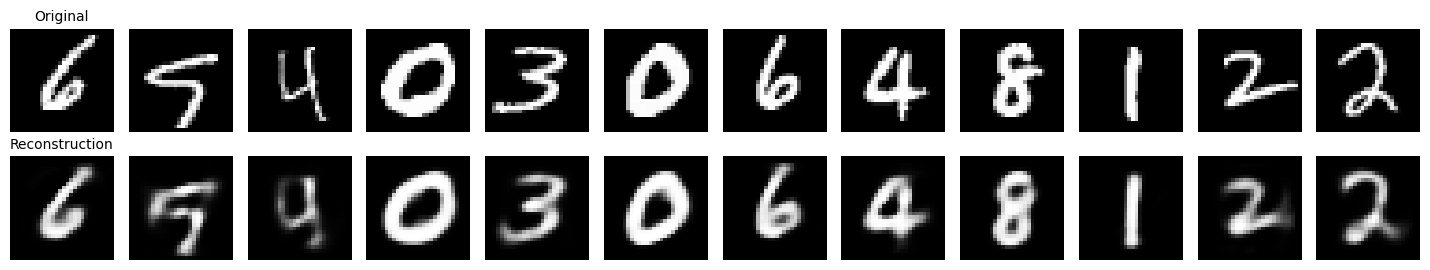

In [8]:
show_reconstructions(sparseAE, train_loader, n=12)

**Reconstructions on the test set**

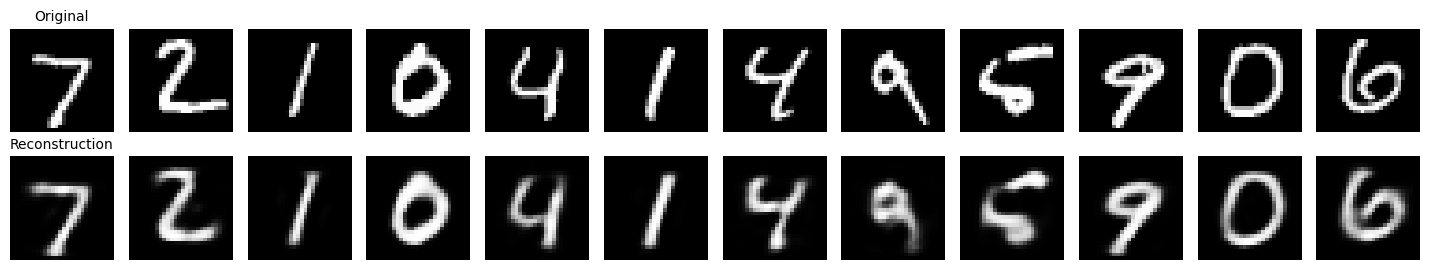

In [9]:
show_reconstructions(sparseAE, test_loader, n=12)

### <font color='blue'>7. What do the latent units capture?</font>

Next, we'd like to get a handle on what aspect of the input is captured by each of the latent units. There are two immediately obvious ways of doing this:
* For a given latent unit, suppose you set it to 1 and set all the other latents to 0. What decoded output is produced?
* Which instances from the training set (or test set) yield the highest activations of that latent unit?

We'll try both of these.

### <font color='blue'>(a) Decoding the latents</font>

Function `decode_latents` takes the trained model and provides a particular kind of visualization of each latent unit:
* That specific unit is set to 1 while all other latents are set to 0.
* The decoding process is applied to get an image.

In [10]:
def decode_latents(model, latent_dim=64, n_cols=8):
  
    device = next(model.parameters()).device
    model.eval()
    # Use one-hot vectors in latent space
    eye = torch.eye(latent_dim, device=device)

    with torch.no_grad():
        imgs = model.decode(eye).view(latent_dim, 28, 28).cpu()

    n_rows = int(np.ceil(latent_dim / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(1.1*n_cols, 1.1*n_rows))
    axes = np.array(axes).reshape(n_rows, n_cols)

    for k in range(n_rows * n_cols):
        r, c = divmod(k, n_cols)
        axes[r, c].axis('off')
        if k < latent_dim:
            axes[r, c].imshow(imgs[k], cmap='gray')

    plt.suptitle('Single-latent decoding', y=1.02)
    plt.tight_layout()
    plt.show()
    
    return imgs

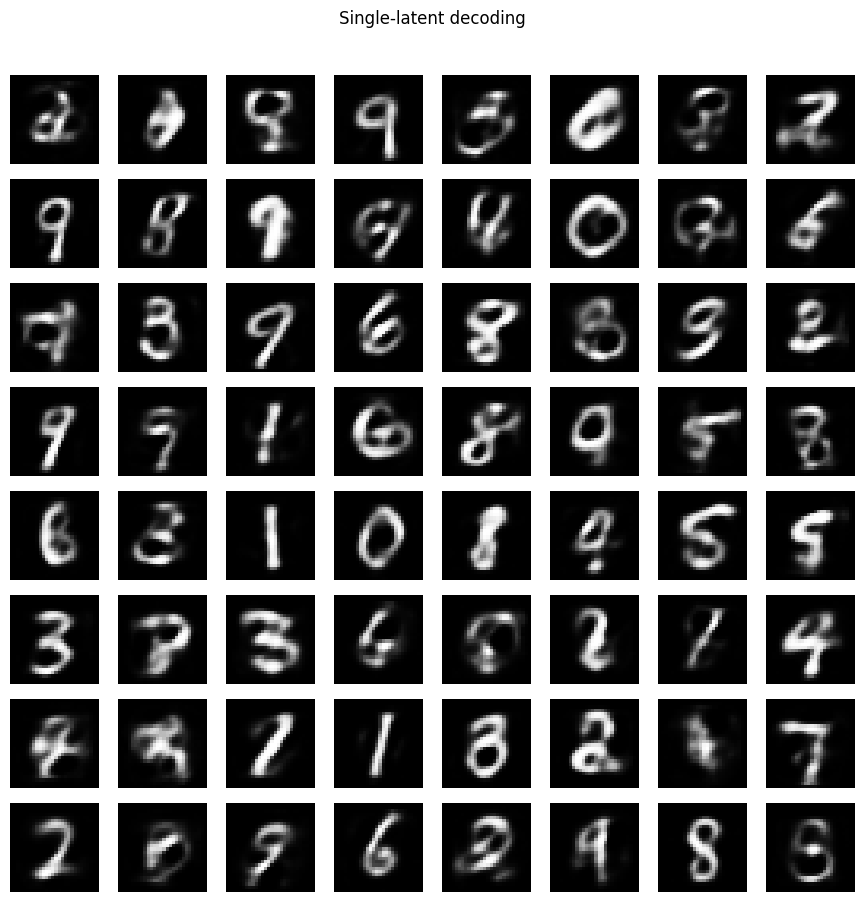

In [11]:
decoded_imgs = decode_latents(sparseAE,latent_dim=64)

### <font color='blue'>(b) Instances that most activate a latent</font>

Next, we will identify the training (or test) instances that most highly activate each latent unit. 

To do this, the first step is to run the training set (or test set) through the encoder and record all the latent activations. These is stored in `activations`. The images in the data set are stored in `images`. Both variables will be used heavily in the subsequent cells.

For a data set of size `N` (e.g. 60000 for the training set):
* `activations` has size `N`-by-`latent_dim`
* `images` has size `N`-by-28-by-28

In [12]:
def get_activations(model, data_loader):

    device = next(model.parameters()).device
    model.eval()

    activations = []
    images = []
    with torch.no_grad():
        for x, _ in data_loader:
            x_flat = x.view(x.size(0), -1).to(device)
            z = model.encode(x_flat).detach().cpu()  # (batch, latent)
            activations.append(z)
            images.append(x.cpu())
            
    activations = torch.cat(activations)
    images = torch.cat(images).squeeze()
    return activations, images
#
# Now call this function
#
activations, images = get_activations(sparseAE, train_loader)

The function `top_examples` takes the index of a latent unit, as well as an integer `k`, and does the following:
* It picks out the `k` data points that produced the highest activation of the specified latent unit
* It prints these out in a grid

In order to do this, it uses `activations` and `images`, obtained earlier.

In [13]:
def top_examples(unit_id, k=10):

    vals, ids = torch.topk(activations[:,unit_id], k=k)
    top_imgs = images[ids]

    fig, axes = plt.subplots(1, k, figsize=(1.2*k, 1.2))
    axes = np.array(axes).reshape(1, k)

    for i in range(k):
        axes[0, i].axis('off')
        axes[0, i].imshow(top_imgs[i], cmap='gray')
        axes[0, i].set_title(f'{vals[i]:.2f}', fontsize=8)
    plt.tight_layout()
    plt.show()

Let's try this out for latent units 0 through 9.

Latent unit 0


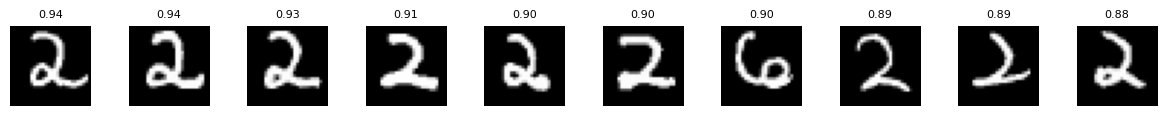

Latent unit 1


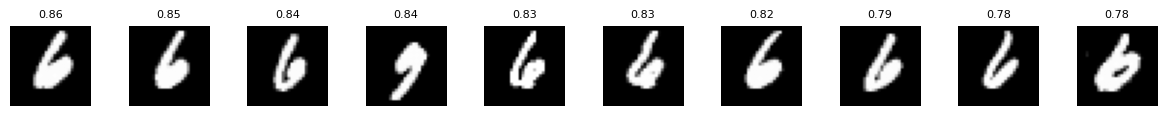

Latent unit 2


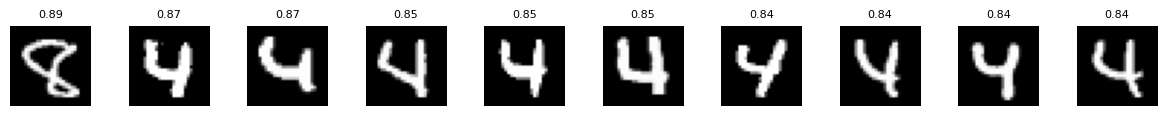

Latent unit 3


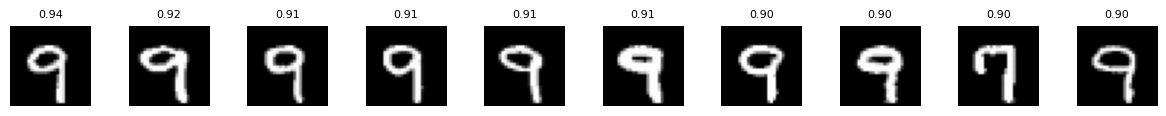

Latent unit 4


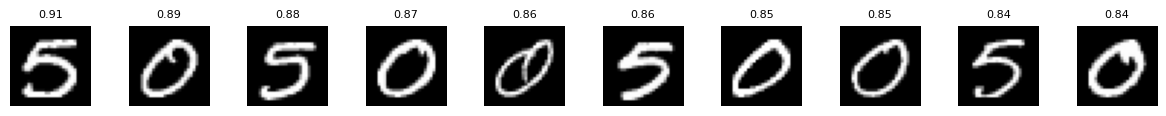

Latent unit 5


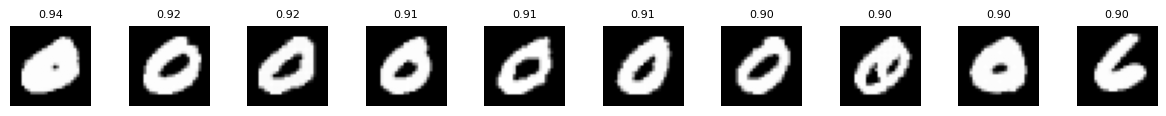

Latent unit 6


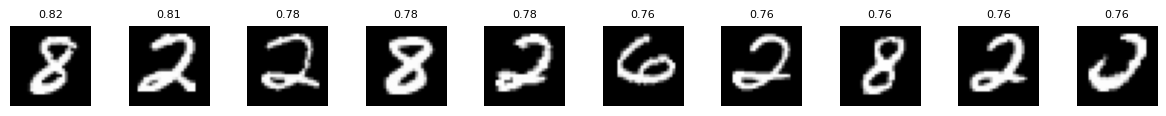

Latent unit 7


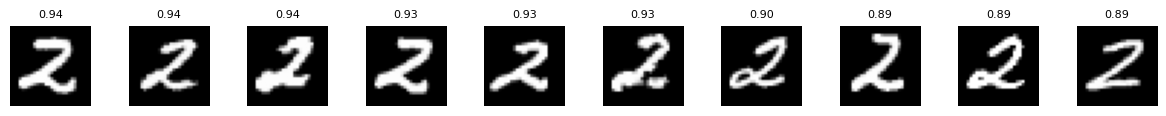

Latent unit 8


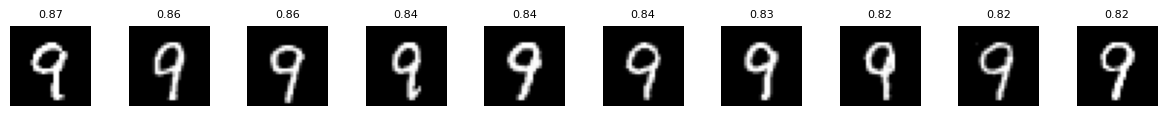

Latent unit 9


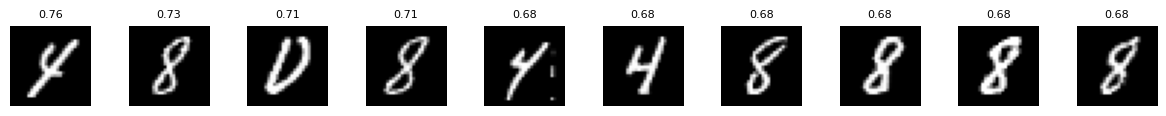

In [14]:
for i in range(10):
    print(f'Latent unit {i}')
    top_examples(unit_id=i)

### <font color='blue'>(c) Putting the two together</font>

Now let's put together the two types of information about the latent units. The following function, `visualize_units`, takes as input:
* `unit_ids`, a list of indices of latent units
* `k`, an integer `k`

For each of the specified units, it first displays the result of decoding that unit by itself, as in (a). It then displays the `k` data instances that most highly activated that unit, as in (b). It is useful to see these two pieces of information side-by-side.

In [15]:
def visualize_units(unit_ids, k=8):

    rows = len(unit_ids)
    cols = k+1
    fig, axes = plt.subplots(rows, cols, figsize=(1.2*cols, 1.2*rows))
    axes = np.array(axes).reshape(rows, cols)
    
    for r in range(rows):
        u = unit_ids[r]
        vals, ids = torch.topk(activations[:,u], k=k)
        top_imgs = images[ids]           # (top_k, 28, 28)

        axes[r,0].axis('off')
        axes[r,0].imshow(decoded_imgs[u], cmap='gray')
        axes[r,0].set_title(f'Decoded unit {u}', fontsize=8)
        for i in range(k):
            axes[r, i+1].axis('off')
            axes[r, i+1].imshow(top_imgs[i], cmap='gray')
            axes[r, i+1].set_title(f'{vals[i]:.2f}', fontsize=8)
    
    plt.tight_layout()
    plt.show()

### <font color='magenta'>To do:</font>
* Apply the function `visualize_units` to 10 of the latent units, chosen at random.
* Include the resulting plot in your writeup.

Randomly chosen latent units: [1, 2, 4, 11, 15, 18, 29, 35, 46, 52]


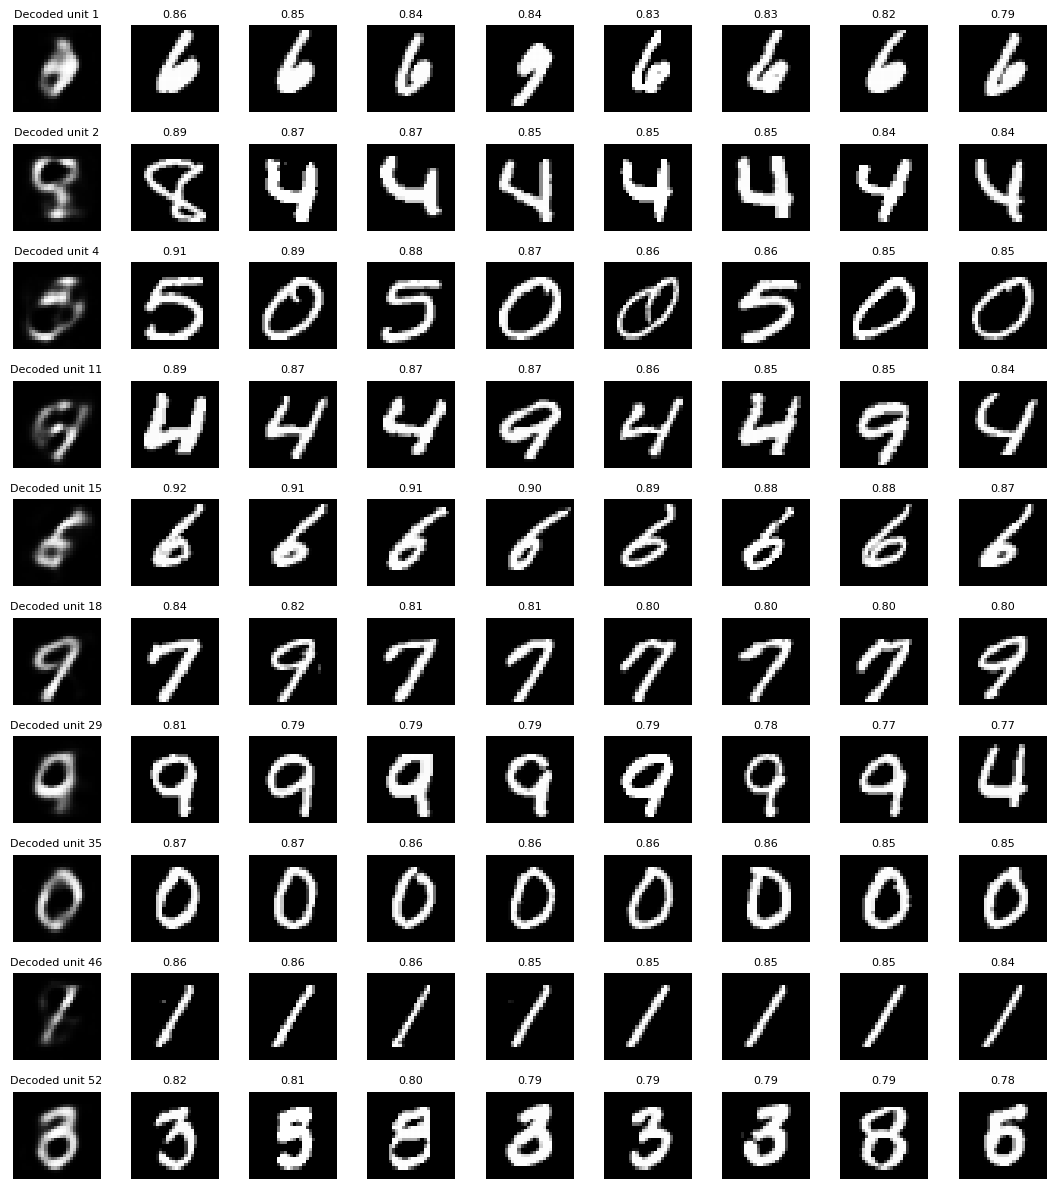

In [16]:
rng = np.random.default_rng(0)
unit_ids = sorted(rng.choice(latent_dim, size=10, replace=False).tolist())
print('Randomly chosen latent units:', unit_ids)
visualize_units(unit_ids, k=8)

### <font color='blue'>8. Is the sparse representation actually sparse?</font>

### <font color='magenta'>To do:</font>
* Using the array `activations` (obtained earlier), compute the average activation of each latent unit. Remember, we wanted these to be around 0.03. Show a plot of these values.
* Again using `activations`, determine, for each instance in the training set, the <em>number</em> of latent units that are significantly activated (say, above 0.05). We can think of this as the "effective sparsity" of the latent representation for that input. What is the mean effective sparsity? Plot a histogram of the effective sparsity levels across the training set.

Mean of average activations: 0.0606
Min: 0.0498 (unit 0),  Max: 0.0738 (unit 5)


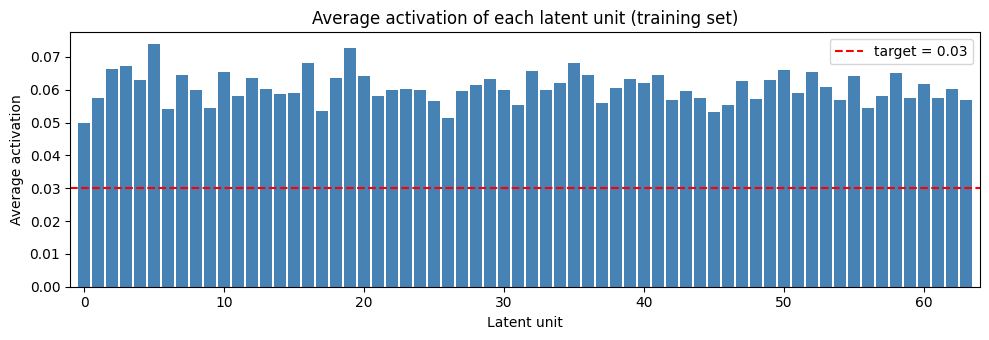

In [17]:
# Average activation of each latent unit over the training set
avg_act = activations.mean(dim=0).numpy()   # shape (latent_dim,)
print(f'Mean of average activations: {avg_act.mean():.4f}')
print(f'Min: {avg_act.min():.4f} (unit {avg_act.argmin()}),  Max: {avg_act.max():.4f} (unit {avg_act.argmax()})')

plt.figure(figsize=(10, 3.5))
plt.bar(np.arange(latent_dim), avg_act, color='steelblue')
plt.axhline(target_sparsity, color='red', linestyle='--', label=f'target = {target_sparsity}')
plt.xlabel('Latent unit')
plt.ylabel('Average activation')
plt.title('Average activation of each latent unit (training set)')
plt.xlim(-1, latent_dim)
plt.legend()
plt.tight_layout()
plt.show()

Mean effective sparsity: 17.15 latent units (out of 64)
Median: 18,  Min: 3,  Max: 32


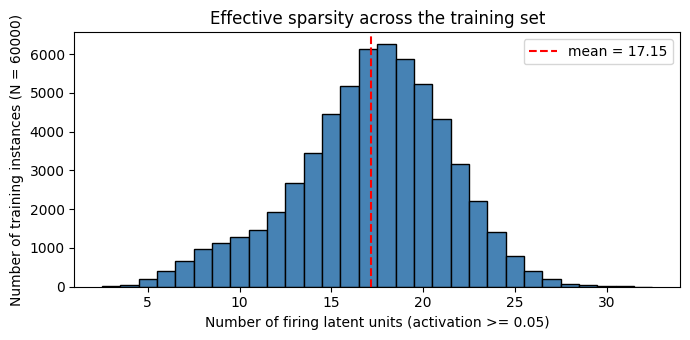

In [18]:
# Effective sparsity: number of latent units with activation >= tau, per training instance
tau = 0.05
eff_sparsity = (activations >= tau).sum(dim=1).numpy()
print(f'Mean effective sparsity: {eff_sparsity.mean():.2f} latent units (out of {latent_dim})')
print(f'Median: {np.median(eff_sparsity):.0f},  Min: {eff_sparsity.min()},  Max: {eff_sparsity.max()}')

plt.figure(figsize=(7, 3.5))
plt.hist(eff_sparsity, bins=np.arange(eff_sparsity.min(), eff_sparsity.max() + 2) - 0.5,
         color='steelblue', edgecolor='black')
plt.axvline(eff_sparsity.mean(), color='red', linestyle='--', label=f'mean = {eff_sparsity.mean():.2f}')
plt.xlabel(f'Number of firing latent units (activation >= {tau})')
plt.ylabel(f'Number of training instances (N = {len(eff_sparsity)})')
plt.title('Effective sparsity across the training set')
plt.legend()
plt.tight_layout()
plt.show()